# Hướng dẫn chi tiết từng bước bằng tiếng Việt để bạn hiểu rõ đoạn code thiết kế bộ lọc FIR High-Pass (Thông thấp qua) này.

Đoạn code này sử dụng kỹ thuật Xử lý Tín hiệu Số (DSP) để loại bỏ các thành phần tần số thấp khỏi tín hiệu và chỉ giữ lại các tần số cao.

---

### **Tổng quan: Chuyện gì đang xảy ra?**

1. **Thiết kế (Design):** Chúng ta tạo ra một cái "rây" toán học (bộ lọc) để chặn các tần số dưới 100 Hz.
2. **Kiểm chứng (Verify):** Vẽ biểu đồ để chứng minh bộ lọc hoạt động đúng về mặt lý thuyết (Đáp ứng tần số).
3. **Thử nghiệm (Test):** Tạo một tín hiệu giả lập trộn lẫn giữa sóng "chậm" (10 Hz) và sóng "nhanh" (300 Hz).
4. **Áp dụng (Apply):** Cho tín hiệu chạy qua bộ lọc.
5. **Kết quả (Result):** Sóng 10 Hz biến mất, chỉ còn lại sóng 300 Hz.

---

### **Bước 1: Nhập thư viện (Import Tools)**

```python
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import freqz, lfilter, firwin

```

* **`numpy` (viết tắt là `np`):** Thư viện toán học tiêu chuẩn. Ở đây dùng để tạo các mảng số (vector) và tính toán sóng sin.
* **`matplotlib.pyplot` (viết tắt là `plt`):** Thư viện dùng để vẽ đồ thị.
* **`scipy.signal`:** Thư viện chuyên dụng cho xử lý tín hiệu.
* `firwin`: **FIR Window**. Hàm này dùng để tính toán và thiết kế các hệ số của bộ lọc.
* `freqz`: Giúp tính toán đáp ứng tần số (để vẽ biểu đồ Bode).
* `lfilter`: **Linear Filter**. Hàm này thực hiện việc lọc thực tế lên dữ liệu.



---

### **Bước 2: Thiết lập thông số (Parameters)**

```python
# -----------------------------
# Thông số chung
# -----------------------------
N = 51
sampling_rate = 1000
window_type = "hamming"

# High-pass: cắt dưới 100 Hz
cutoff_hp = 100  # Hz

```

* **`N = 51`:** Đây là **Bậc (Order)** hay số lượng **Taps** của bộ lọc. Nó đại diện cho số lượng điểm (hệ số) trong bộ lọc.
* *Quy tắc:* `N` càng cao thì bộ lọc càng sắc (lọc càng sạch) nhưng tính toán càng chậm. Số lẻ thường được ưa chuộng cho bộ lọc FIR đối xứng.


* **`sampling_rate = 1000`:** Tần số lấy mẫu. Nghĩa là hệ thống ghi nhận 1000 điểm dữ liệu mỗi giây.
* **`cutoff_hp = 100`:** Tần số cắt. Mọi thứ **dưới** 100 Hz sẽ bị chặn. Mọi thứ **trên** 100 Hz sẽ được cho qua.

---

### **Bước 3: Tạo bộ lọc (Phần "Bộ não")**

```python
# Tạo FIR high-pass
b_hp = firwin(N, cutoff=cutoff_hp, pass_zero=False, window=window_type, fs=sampling_rate)

```

Đây là dòng quan trọng nhất. `firwin` trả về một mảng `b_hp` chứa 51 con số (hệ số lọc).

* **`cutoff=cutoff_hp`**: Đặt ngưỡng là 100 Hz.
* **`pass_zero=False`**: Đây là tham số quyết định loại bộ lọc.
* Nếu `pass_zero=True`: Cho phép 0 Hz (DC) đi qua  Bộ lọc thông thấp (Low-pass).
* Nếu `pass_zero=False`: Chặn 0 Hz  **Bộ lọc thông cao (High-pass)**.


* **`fs=sampling_rate`**: Báo cho hàm biết rằng con số "100" kia là 100 Hz so với tốc độ lấy mẫu 1000 Hz.

---

### **Bước 4: Kiểm tra trực quan (Đáp ứng tần số)**

Trước khi lọc, ta cần xem bộ lọc có "chuẩn" không bằng biểu đồ.

```python
# Đáp ứng tần số
w, h = freqz(b_hp, worN=8000, fs=sampling_rate)

```

* `freqz` tính toán hành vi của bộ lọc trên toàn bộ dải tần.

```python
plt.plot(w, 20*np.log10(np.maximum(np.abs(h), 1e-12)))

```

* **`np.abs(h)`**: Lấy độ lớn (biên độ) của phản hồi.
* **`20*np.log10(...)`**: Chuyển đổi biên độ sang đơn vị **Decibels (dB)**. Kỹ sư dùng dB vì độ mạnh yếu của tín hiệu thay đổi rất lớn.
* **0 dB** = Tín hiệu đi qua nguyên vẹn (Hệ số khuếch đại = 1).
* **-20 dB** = Tín hiệu bị giảm còn 1/10.
* **-100 dB** = Tín hiệu coi như bị triệt tiêu hoàn toàn.


* Biểu đồ sẽ cho thấy tần số thấp (0-100 Hz) bị kéo xuống rất thấp (bị chặn) và tần số cao (>100 Hz) nằm gần mức 0 dB (được qua).

---

### **Bước 5: Tạo tín hiệu thử nghiệm (Test Signal)**

Chúng ta tạo một tín hiệu "bẩn" để thử lọc.

```python
# Test signal: 10 Hz + 300 Hz
t = np.linspace(0, 1, sampling_rate, endpoint=False)
x = np.sin(2*np.pi*10*t) + np.sin(2*np.pi*300*t)

```

* **`t`**: Mảng thời gian từ 0 đến 1 giây.
* **`x`**: Cộng hai sóng hình sin lại với nhau:
1. **10 Hz**: Sóng chậm (nằm dưới mức cắt 100 Hz). Đây là "nhiễu" chúng ta muốn loại bỏ.
2. **300 Hz**: Sóng nhanh (nằm trên mức cắt 100 Hz). Đây là dữ liệu chúng ta muốn giữ.



---

### **Bước 6: Thực hiện lọc**

```python
# Lọc (Filtering)
y_hp = lfilter(b_hp, 1.0, x)

```

* **`lfilter`**: Áp dụng bộ lọc `b_hp` lên tín hiệu `x`.
* **`1.0`**: Đây là mẫu số của hàm truyền. Đối với bộ lọc FIR, số này luôn là 1.0 (vì FIR không có phản hồi ngược - feedback).
* **`y_hp`**: Đây là **Tín hiệu ngõ ra**. Về lý thuyết, nó chỉ còn chứa sóng 300 Hz.

---

### **Bước 7: Xem kết quả (Miền thời gian)**

Code vẽ ra 2 biểu đồ:

1. **Biểu đồ trên (`Tín hiệu gốc`):** Tín hiệu hỗn độn. Bạn sẽ thấy một sóng lớn đi chậm, và trên lưng nó có các dao động nhỏ rất nhanh.
2. **Biểu đồ dưới (`Sau high-pass`):** Kết quả sạch. Sóng chậm 10 Hz đã biến mất, tín hiệu dao động quanh trục 0. Bạn chỉ còn thấy các dao động nhanh 300 Hz.

### **Tóm tắt các khái niệm chính**

| Khái niệm | Giải thích | Trong code |
| --- | --- | --- |
| **FIR** | Finite Impulse Response. Một loại bộ lọc số ổn định. | `firwin` dùng để tạo ra nó. |
| **High-pass** | Cho tần số cao qua, chặn tần số thấp. | `pass_zero=False` quy định điều này. |
| **Cutoff** | Tần số cắt (ranh giới chặn/cho qua). | `cutoff_hp = 100`. |
| **Order (N)** | Độ phức tạp của bộ lọc. Càng cao lọc càng gắt. | `N = 51`. |

**Bạn có muốn tôi hướng dẫn cách sửa đoạn code này thành bộ lọc Low-Pass (giữ lại 10 Hz, bỏ 300 Hz) không?**

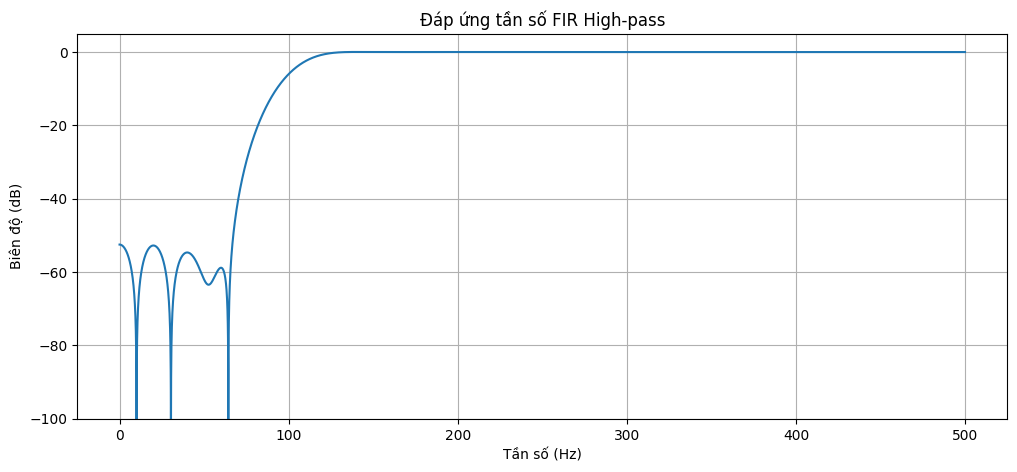

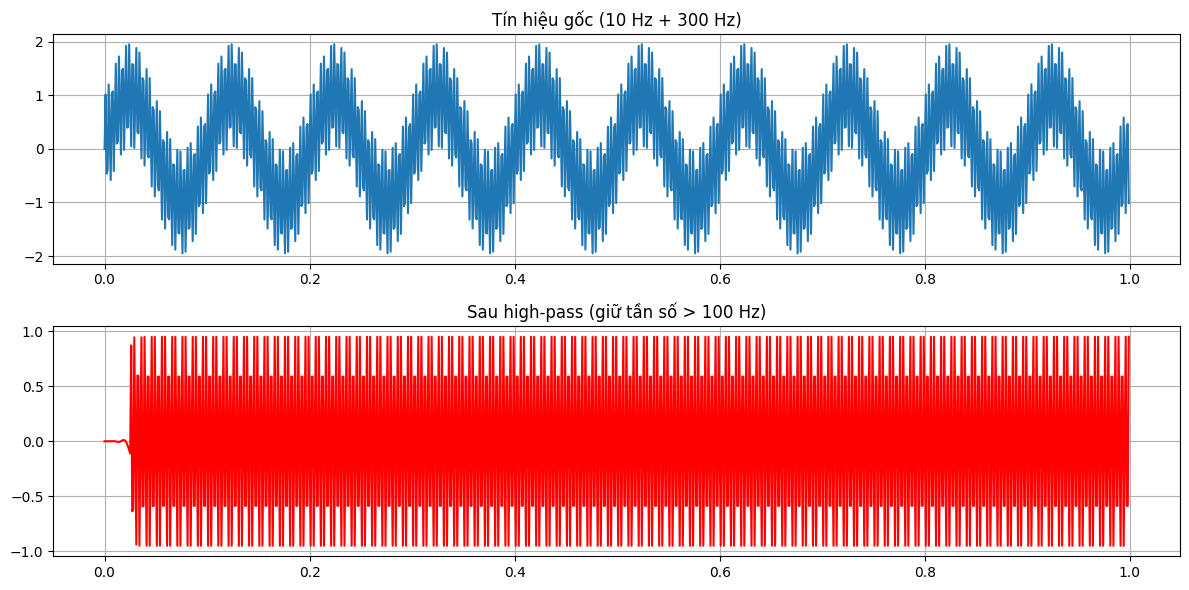

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import freqz, lfilter, firwin

# -----------------------------
# Thông số chung
# -----------------------------
N = 51
sampling_rate = 1000
window_type = "hamming"

# High-pass: cắt dưới 100 Hz (ví dụ)
cutoff_hp = 100  # Hz

# Tạo FIR high-pass
b_hp = firwin(N, cutoff=cutoff_hp, pass_zero=False, window=window_type, fs=sampling_rate)

# Đáp ứng tần số
w, h = freqz(b_hp, worN=8000, fs=sampling_rate)
plt.figure(figsize=(12, 5))
plt.plot(w, 20*np.log10(np.maximum(np.abs(h), 1e-12)))
plt.title("Đáp ứng tần số FIR High-pass")
plt.xlabel("Tần số (Hz)")
plt.ylabel("Biên độ (dB)")
plt.grid(True)
plt.ylim(-100, 5)
plt.show()

# Test signal: 10 Hz + 300 Hz
t = np.linspace(0, 1, sampling_rate, endpoint=False)
x = np.sin(2*np.pi*10*t) + np.sin(2*np.pi*300*t)

# Lọc
y_hp = lfilter(b_hp, 1.0, x)

# Plot
plt.figure(figsize=(12, 6))
plt.subplot(2,1,1)
plt.plot(t, x)
plt.title("Tín hiệu gốc (10 Hz + 300 Hz)")
plt.grid(True)
plt.subplot(2,1,2)
plt.plot(t, y_hp, color="red")
plt.title("Sau high-pass (giữ tần số > 100 Hz)")
plt.grid(True)
plt.tight_layout()
plt.show()

## Để thay đổi loại bộ lọc FIR 

Bạn thay đổi trong hàm `scipy.signal.firwin`, bạn chỉ cần tập trung vào 2 tham số quan trọng nhất:

1. **`cutoff`**: Tần số cắt (một giá trị đơn hoặc một danh sách giá trị).
2. **`pass_zero`**: Quyết định xem tần số 0 Hz (tín hiệu một chiều - DC) được **cho qua (True)** hay **bị chặn (False)**.

Dưới đây là hướng dẫn cấu hình chi tiết cho từng loại:

---

### 1. Bộ lọc Thông thấp (Low-Pass Filter)

**Mục đích:** Giữ lại tần số thấp, loại bỏ tần số cao.

* **Logic:** Tín hiệu bắt đầu từ 0 Hz được phép đi qua.
* **Cấu hình:**
* `cutoff`: Một giá trị đơn (ví dụ: 100 Hz).
* `pass_zero`: **`True`** (Cho phép 0 Hz đi qua).



```python
# Ví dụ: Giữ lại tần số dưới 100 Hz
cutoff_lp = 100
b_lp = firwin(N, cutoff=cutoff_lp, pass_zero=True, window=window_type, fs=sampling_rate)

```

---

### 2. Bộ lọc Thông dải (Band-Pass Filter)

**Mục đích:** Chỉ giữ lại một khoảng tần số ở giữa (ví dụ: từ 150 Hz đến 250 Hz). Chặn cả thấp và cao.

* **Logic:** Tín hiệu tại 0 Hz bị chặn.
* **Cấu hình:**
* `cutoff`: Một danh sách 2 giá trị `[tần_số_thấp, tần_số_cao]`.
* `pass_zero`: **`False`** (Chặn 0 Hz).



```python
# Ví dụ: Chỉ giữ lại tín hiệu từ 150 Hz đến 250 Hz
cutoff_bp = [150, 250]
b_bp = firwin(N, cutoff=cutoff_bp, pass_zero=False, window=window_type, fs=sampling_rate)

```

---

### 3. Bộ lọc Chặn dải (Band-Stop / Notch Filter)

**Mục đích:** Loại bỏ một khoảng tần số cụ thể (ví dụ: nhiễu nguồn điện 50Hz, hoặc cắt bỏ khoảng 150-250 Hz), nhưng giữ lại phần thấp hơn và cao hơn khoảng đó.

* **Logic:** Tín hiệu tại 0 Hz được phép đi qua (vì nó nằm trước dải bị chặn).
* **Cấu hình:**
* `cutoff`: Một danh sách 2 giá trị `[tần_số_thấp, tần_số_cao]`.
* `pass_zero`: **`True`** (Cho phép 0 Hz đi qua).



```python
# Ví dụ: Loại bỏ tín hiệu trong khoảng 150 Hz đến 250 Hz (giữ lại <150 và >250)
cutoff_bs = [150, 250]
b_bs = firwin(N, cutoff=cutoff_bs, pass_zero=True, window=window_type, fs=sampling_rate)

```

---

### Bảng tóm tắt nhanh (Cheat Sheet)

| Loại bộ lọc | `cutoff` (Hz) | `pass_zero` | Giải thích `pass_zero` |
| --- | --- | --- | --- |
| **High-Pass** | Giá trị đơn (VD: `100`) | `False` | Chặn 0 Hz để chỉ lấy cao. |
| **Low-Pass** | Giá trị đơn (VD: `100`) | `True` | Cho 0 Hz qua để lấy thấp. |
| **Band-Pass** | List 2 số (VD: `[150, 250]`) | `False` | Chặn 0 Hz, bắt đầu dải thông ở `150`. |
| **Band-Stop** | List 2 số (VD: `[150, 250]`) | `True` | Cho 0 Hz qua, bắt đầu chặn ở `150`. |

### Lưu ý quan trọng về Tần số Nyquist

Khi đặt giá trị cho `cutoff`, bạn phải luôn nhớ quy tắc vàng:

> **Tần số cắt phải nhỏ hơn một nửa tần số lấy mẫu (Nyquist Rate).**

Với `sampling_rate = 1000`, thì `cutoff` tối đa chỉ được là **499 Hz** (nhỏ hơn 500 Hz). Nếu bạn đặt `cutoff = 600`, chương trình sẽ báo lỗi `ValueError`.



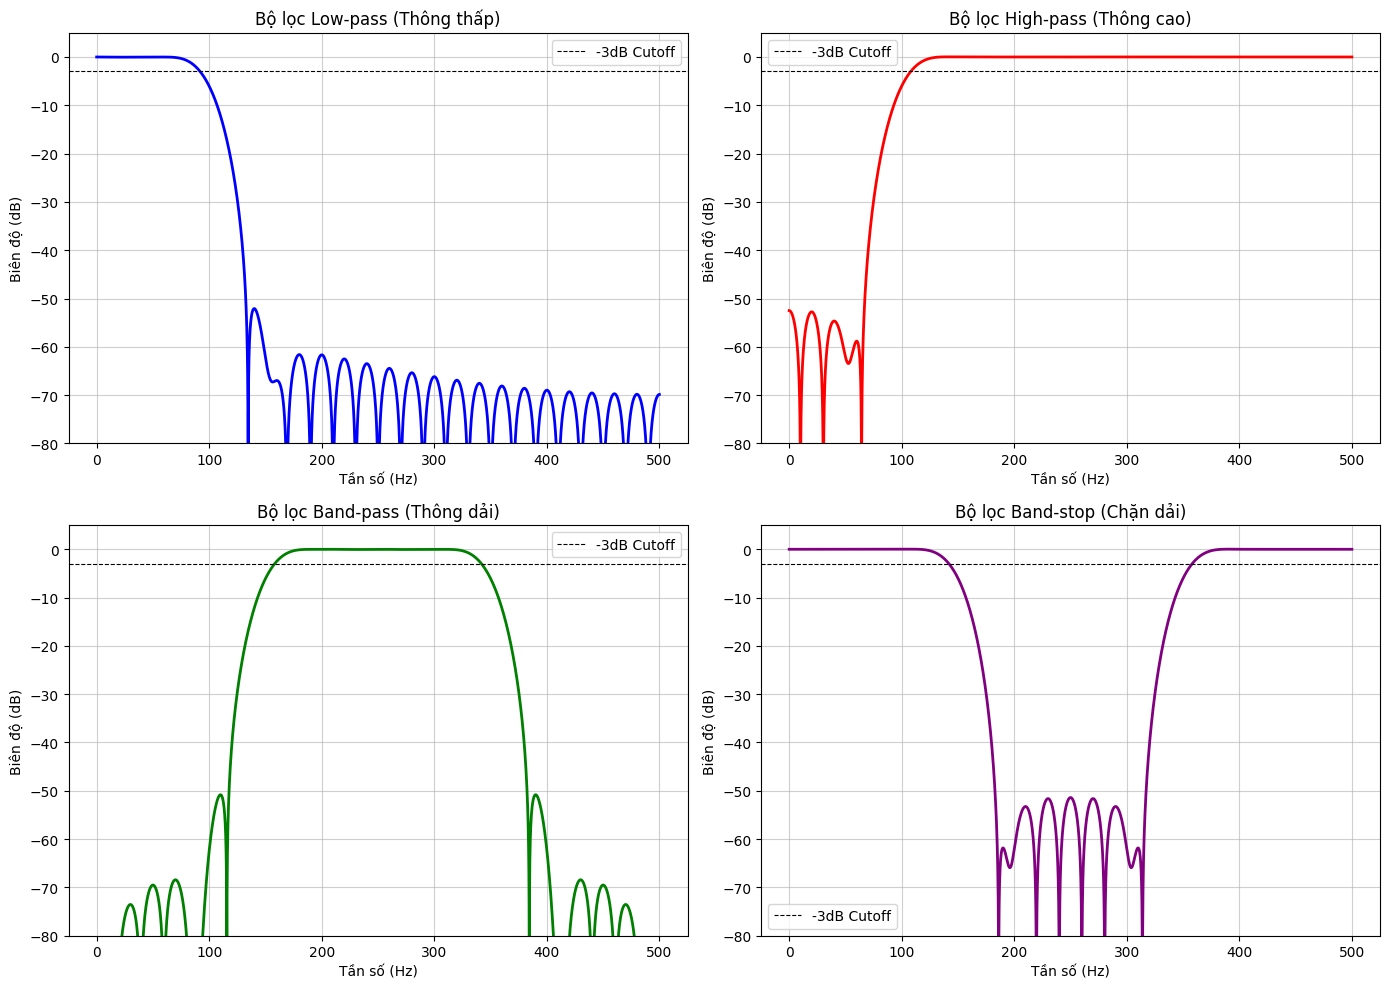

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import firwin, freqz

# 1. Thông số chung
N = 51                # Bậc bộ lọc (số lượng hệ số)
fs = 1000             # Tần số lấy mẫu (Hz)
nyquist = fs / 2      # Tần số Nyquist = 500 Hz

# 2. Cấu hình cho 4 loại bộ lọc
# Lưu ý: Cutoff phải nhỏ hơn Nyquist (500 Hz)
filters_config = [
    {
        "name": "Low-pass (Thông thấp)",
        "cutoff": 100,          # Cắt tại 100 Hz
        "pass_zero": True,      # Cho 0 Hz qua
        "color": "blue"
    },
    {
        "name": "High-pass (Thông cao)",
        "cutoff": 100,          # Cắt tại 100 Hz
        "pass_zero": False,     # Chặn 0 Hz
        "color": "red"
    },
    {
        "name": "Band-pass (Thông dải)",
        "cutoff": [150, 350],   # Lấy từ 150 đến 350 Hz
        "pass_zero": False,     # Chặn 0 Hz
        "color": "green"
    },
    {
        "name": "Band-stop (Chặn dải)",
        "cutoff": [150, 350],   # Bỏ từ 150 đến 350 Hz
        "pass_zero": True,      # Cho 0 Hz qua
        "color": "purple"
    }
]

# 3. Vẽ đồ thị
plt.figure(figsize=(14, 10))

for i, config in enumerate(filters_config):
    # Tạo bộ lọc
    b = firwin(N, cutoff=config["cutoff"], pass_zero=config["pass_zero"], fs=fs)
    
    # Tính đáp ứng tần số (Frequency Response)
    w, h = freqz(b, worN=8000, fs=fs)
    
    # Chuyển sang dB
    h_db = 20 * np.log10(np.maximum(np.abs(h), 1e-12))
    
    # Vẽ lên vị trí tương ứng (lưới 2x2)
    plt.subplot(2, 2, i + 1)
    plt.plot(w, h_db, color=config["color"], linewidth=2)
    
    # Trang trí
    plt.title(f"Bộ lọc {config['name']}")
    plt.xlabel("Tần số (Hz)")
    plt.ylabel("Biên độ (dB)")
    plt.grid(True, which='both', alpha=0.6)
    
    # Vẽ vùng đánh dấu để dễ nhìn
    plt.axhline(y=-3, color='black', linestyle='--', linewidth=0.8, label="-3dB Cutoff")
    plt.ylim(-80, 5)  # Giới hạn trục Y để nhìn rõ hình dáng
    plt.legend()

plt.tight_layout()
plt.show()